# 1. Дизайн эксперимента и проверки корректности

**Контекст.** Cookie Cats — мобильная головоломка «три в ряд». По мере прохождения игрок упирается в ворота: дальше можно пройти, только подождав или заплатив. В эксперименте новым игрокам случайно назначали ворота на 30-м (контроль, `gate_30`) или на 40-м уровне (тест, `gate_40`).

**Вопрос продакта:** переносить ли ворота на 40-й уровень?

**Данные** — 90 189 игроков, по одному на строку:

| Поле | Смысл |
|---|---|
| `userid` | ID игрока |
| `version` | группа: `gate_30` или `gate_40` |
| `sum_gamerounds` | число сыгранных раундов за первые 14 дней после установки |
| `retention_1` | вернулся ли через 1 день после установки |
| `retention_7` | вернулся ли через 7 дней после установки |

Чего в данных нет (и это повлияет на методы): дат и времени, номера уровня, метрик до эксперимента, выручки.

**План ноутбука:** записать дизайн теста, проверить сплит (SRM), проверить, что группы одинаковы до воздействия, посмотреть на распределение раундов и выбросы.

In [1]:
import sys
sys.path[:0] = ["src", "../src"]  # notebooks/src — стиль графиков, src — библиотека abtest
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from abtest import stats as S
from _style import setup, commas, percent, num, pct, pp, pval, thousands, COLORS, LABELS, CONTROL, TEST, NEUTRAL, MUTED, TEXT
setup()

df = pd.read_csv("../data/cookie_cats.csv")
A, B = df[df.version == "gate_30"], df[df.version == "gate_40"]
print(f"{thousands(len(df))} игроков, дубликатов userid: {df.userid.duplicated().sum()}, пропусков: {df.isna().sum().sum()}")
df.head()

90 189 игроков, дубликатов userid: 0, пропусков: 0


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


## 1.1. Дизайн «до запуска»

Записываем решения так, будто тест ещё не начался: это защищает от подгонки выводов под результат. Предрегистрации у этого эксперимента не было, поэтому дизайн восстановлен по описанию датасета.

- **Гипотеза.** Перенос ворот меняет 7-дневное удержание. Направление заранее неизвестно, поэтому тест двусторонний.
  - Довод «за»: без раннего барьера игрок дольше играет и сильнее втягивается.
  - Довод «против»: ворота работают как пауза; отдохнувший игрок возвращается охотнее, а без паузы игра быстрее надоедает.
- **Целевая метрика:** `retention_7` — доля игроков, вернувшихся через неделю. Это ближе всего к долгосрочной ценности игрока.
- **Вторичная метрика:** `retention_1`.
- **Барьерная метрика (guardrail):** `sum_gamerounds` — вовлечённость не должна заметно просесть.
- **Параметры:** α = 0,05, мощность 80%; для вторичной и барьерной метрик — поправка Холма на множественные сравнения.
- **Правило решения:** переносим ворота, только если `retention_7` в тесте значимо выше и барьерная метрика не просела. Если различий нет, оставляем 30: изменение не бесплатно.

## 1.2. Обзор групп

In [2]:
g = df.groupby("version")
pd.DataFrame({
    "игроков": g.size().map(thousands),
    "доля игроков": (g.size() / len(df)).map(lambda v: pct(v, 2)),
    "retention_1": g.retention_1.mean().map(lambda v: pct(v, 2)),
    "retention_7": g.retention_7.mean().map(lambda v: pct(v, 2)),
    "раунды, среднее": g.sum_gamerounds.mean().map(lambda v: num(v, 1)),
    "раунды, медиана": g.sum_gamerounds.median().map(lambda v: num(v, 0)),
})

,игроков,доля игроков,retention_1,retention_7,"раунды, среднее","раунды, медиана"
version,,,,,,
gate_30,44 700,"49,56%","44,82%","19,02%","52,5",17
gate_40,45 489,"50,44%","44,23%","18,20%","51,3",16


## 1.3. Проверка сплита (SRM — Sample Ratio Mismatch)

Первое, что проверяют в любом A/B-тесте: совпадает ли фактическое соотношение групп с задуманным. Если сплит «кривой», возможно, часть игроков терялась или назначалась неслучайно, и тогда сравнение групп некорректно. Предполагаем задуманное деление 50/50.

In [3]:
counts = [len(A), len(B)]
srm = S.srm_test(counts)
print(f"Размеры групп: {thousands(counts[0])} и {thousands(counts[1])}, доля теста {pct(srm['observed_share'][1], 2)}")
print(f"χ² = {num(srm['chi2'])}, p-value = {pval(srm['p_value'])}")

Размеры групп: 44 700 и 45 489, доля теста 50,44%
χ² = 6,90, p-value = 0,0086


**Интерпретация.** p ≈ 0,009 — это ниже 0,05, но выше порога 0,001, который обычно используют для SRM. Порог такой строгий, потому что проверку запускают на каждом тесте, и при пороге 0,05 ложные тревоги были бы в каждом двадцатом эксперименте. Перекос небольшой: 0,44 п.п. от равного деления, около 400 игроков.

Мы не знаем, задумывался ли сплит ровно 50/50, и не видим логов рандомизации. Вывод: формально тревоги нет, но это сигнал проверить механизм распределения по группам. Ниже — косвенная проверка.

## 1.4. Косвенная проверка рандомизации: поведение до ворот

Чтобы упереться в ворота на 30-м уровне, нужно пройти 29 уровней, а на каждый уровень нужен хотя бы один раунд. Значит, игрок, сыгравший меньше 29 раундов, ни одних ворот не видел, и до этой границы группы играют в одинаковую игру. Доля таких игроков должна совпадать с точностью до случайности.

Оговорки: раунд ≠ уровень (уровень можно переигрывать), поэтому граница консервативная — до неё ворот точно не было. Порог выбран после просмотра данных, поэтому ниже есть проверка чувствительности к нему.

In [4]:
GATE_FREE = 29  # меньше 29 раундов — до ворот точно не дошёл
pre = S.two_proportion_test((A.sum_gamerounds < GATE_FREE).sum(), len(A), (B.sum_gamerounds < GATE_FREE).sum(), len(B))
print(f"Доля игроков с < {GATE_FREE} раундов: контроль {pct(pre['p_a'], 2)}, тест {pct(pre['p_b'], 2)}")
print(f"Разница {pp(pre['diff'])} п.п., 95% ДИ [{pp(pre['ci'][0])}; {pp(pre['ci'][1])}] п.п., p = {pval(pre['p_value'])}")

Доля игроков с < 29 раундов: контроль 62,06%, тест 62,80%
Разница +0,73 п.п., 95% ДИ [+0,10; +1,36] п.п., p = 0,023


In [5]:
# чувствительность к порогу: результат не должен держаться на одном удачном значении
rows = []
for k in [10, 15, 20, 25, 29]:
    r = S.two_proportion_test((A.sum_gamerounds < k).sum(), len(A), (B.sum_gamerounds < k).sum(), len(B))
    rows.append({"порог, раундов": k, "контроль": pct(r["p_a"], 2), "тест": pct(r["p_b"], 2),
                 "разница, п.п.": pp(r["diff"]), "p-value": pval(r["p_value"])})
pd.DataFrame(rows).set_index("порог, раундов")

,контроль,тест,"разница, п.п.",p-value
"порог, раундов",,,,
10,"37,66%","38,26%","+0,59","0,066"
15,"46,49%","47,36%","+0,87","0,0090"
20,"53,61%","54,53%","+0,92","0,0056"
25,"58,79%","59,71%","+0,91","0,0053"
29,"62,06%","62,80%","+0,73","0,023"


Ту же проверку удобно увидеть целиком. Для каждого k считаем долю игроков, сыгравших хотя бы k раундов, и разницу этих долей между группами с 95% доверительной полосой.

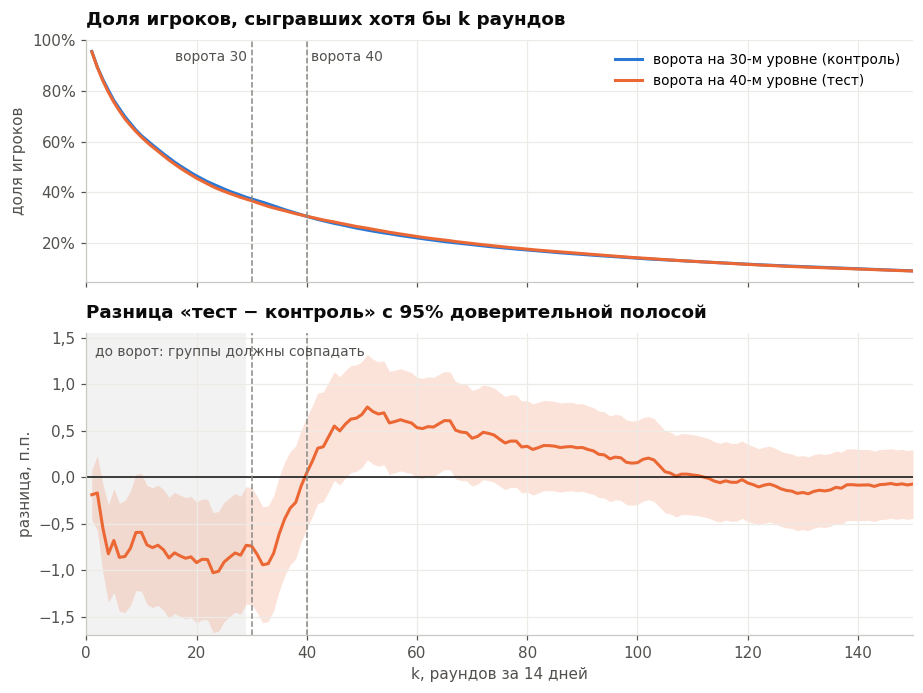

In [6]:
ks = np.arange(1, 151)
sa = np.array([(A.sum_gamerounds >= k).mean() for k in ks])
sb = np.array([(B.sum_gamerounds >= k).mean() for k in ks])
diff = (sb - sa) * 100
half = 1.96 * np.sqrt(sa * (1 - sa) / len(A) + sb * (1 - sb) / len(B)) * 100

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8.5, 6.4), sharex=True, gridspec_kw={"height_ratios": [1, 1.25]})
ax1.plot(ks, sa, color=CONTROL, label=LABELS["gate_30"])
ax1.plot(ks, sb, color=TEST, label=LABELS["gate_40"])
percent(ax1)
ax1.set(title="Доля игроков, сыгравших хотя бы k раундов", ylabel="доля игроков")
ax1.legend(loc="upper right")

ax2.axvspan(0, GATE_FREE, color=NEUTRAL, alpha=0.10, lw=0)
ax2.text(1.5, 1.3, "до ворот: группы должны совпадать", fontsize=9, color=MUTED)
ax2.fill_between(ks, diff - half, diff + half, color=TEST, alpha=0.18, lw=0)
ax2.plot(ks, diff, color=TEST)
ax2.axhline(0, color=TEXT, lw=1)
for ax in (ax1, ax2):
    for x in (30, 40):
        ax.axvline(x, color=NEUTRAL, lw=1, ls="--")
ax1.text(29.2, 0.92, "ворота 30", fontsize=9, color=MUTED, ha="right")
ax1.text(40.8, 0.92, "ворота 40", fontsize=9, color=MUTED, ha="left")
ax2.set_ylim(-1.7, 1.55); ax2.set_xlim(0, 150)
commas(ax2)
ax2.set(title="Разница «тест − контроль» с 95% доверительной полосой", xlabel="k, раундов за 14 дней", ylabel="разница, п.п.")
fig.tight_layout()

**Что видно.**

- **До ворот (k < 29)** тестовая группа уже отстаёт на 0,6–0,9 п.п., и полоса почти везде ниже нуля. В тесте доля игроков с < 29 раундов выше на 0,73 п.п. (p ≈ 0,02); перекос того же знака держится при любом пороге от 10 до 29 и значим везде, кроме порога 10. Вместе с SRM (p ≈ 0,009) это намёк на то, что группы с самого начала немного различались. Возможно, у обеих аномалий одна причина.
- **Примерно с 40 до 100 раундов** кривые меняются местами: в контроле часть игроков останавливается на воротах 30-го уровня, а в тесте продолжает играть до 40-го. Так выглядит само воздействие.
- **Ближе к 150 раундам** разница исчезает: до этих рубежей доходят увлечённые игроки, для которых положение ворот уже не важно.

**Что это значит для анализа:**
- Это не повод выбросить тест: перекос маленький, а обе проверки не проходят строгий порог 0,001.
- Но это повод не переоценивать маленькие эффекты: если наблюдаемая разница в удержании того же порядка (~0,5–1 п.п.), часть её может объясняться неидеальной рандомизацией. В ноутбуке 2 (раздел 2.6) оценка эффекта будет скорректирована на этот дисбаланс.
- В отчёте продакту это будет отдельной оговоркой и рекомендацией проверить механизм сплита.

## 1.5. Распределение раундов и выбросы

In [7]:
q = g.sum_gamerounds.quantile([0.5, 0.9, 0.99, 0.999]).unstack()
pd.DataFrame({
    "медиана": q[0.5].map(lambda v: num(v, 0)), "90%": q[0.9].map(lambda v: num(v, 0)),
    "99%": q[0.99].map(lambda v: num(v, 0)), "99,9%": q[0.999].map(lambda v: num(v, 0)),
    "максимум": g.sum_gamerounds.max().map(thousands),
    "доля с 0 раундов": (df.sum_gamerounds == 0).groupby(df.version).mean().map(lambda v: pct(v, 2)),
})

,медиана,90%,99%,"99,9%",максимум,доля с 0 раундов
version,,,,,,
gate_30,17,135,493,1053,49 854,"4,33%"
gate_40,16,134,492,1086,2 640,"4,52%"


Распределение с очень тяжёлым хвостом: медиана 16–17 раундов, а максимум — 49 854 раунда за 14 дней у одного игрока в контроле (это больше 3500 раундов в день — скорее всего бот или ошибка логирования). Следующий по величине — 2961 (тоже в контроле; максимум в тесте — 2640).

**Решение (принимаем до сравнения групп):** игроков не удаляем — в основной анализ идут все распределённые. Для раундов используем устойчивые методы (ранговый тест, bootstrap медианы, t-тест на логарифме), а среднее показываем дважды: со всеми игроками и с винзоризацией на 99,9-м перцентиле — как проверку чувствительности.

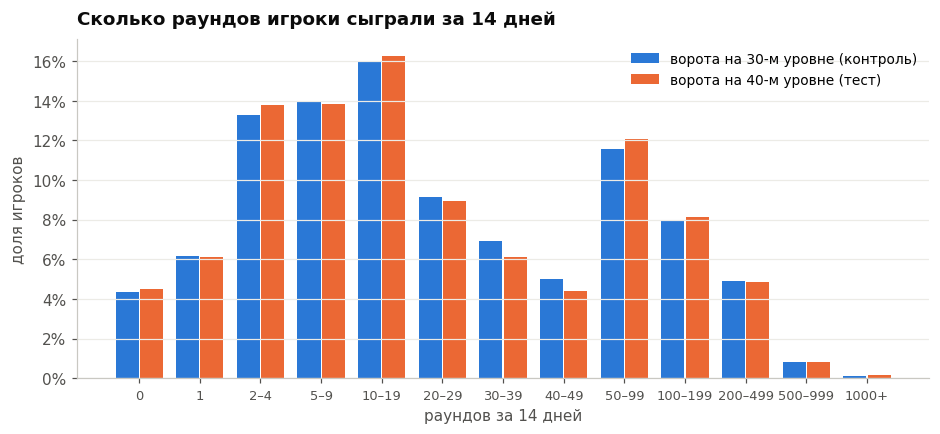

In [8]:
buckets = [0, 1, 2, 5, 10, 20, 30, 40, 50, 100, 200, 500, 1000, np.inf]   # корзины растут примерно геометрически
names = ["0", "1", "2–4", "5–9", "10–19", "20–29", "30–39", "40–49", "50–99", "100–199", "200–499", "500–999", "1000+"]
x = np.arange(len(names))
fig, ax = plt.subplots(figsize=(10, 4))
for i, (v, gr) in enumerate(g):
    share = pd.cut(gr.sum_gamerounds, buckets, right=False).value_counts(sort=False).values / len(gr)
    ax.bar(x + (i - 0.5) * 0.4, share, width=0.38, color=COLORS[v], label=LABELS[v])
ax.set_xticks(x, names, fontsize=8.5)
ax.grid(axis="x", visible=False)
percent(ax, digits=0)
ax.set(title="Сколько раундов игроки сыграли за 14 дней", xlabel="раундов за 14 дней", ylabel="доля игроков")
ax.legend(loc="upper right")

Корзины растут примерно в два раза, иначе на графике не уместить хвост длиной в четыре порядка. Группы почти совпадают. Разница видна вокруг ворот: в корзинах 30–39 и 40–49 больше игроков контроля, часть из них застряла на воротах 30-го уровня. В тесте такие игроки идут дальше, поэтому у теста больше корзина 50–99. Одна точка на 49 854 раундах сдвигает среднее контроля примерно на 1,1 раунда, поэтому в ноутбуке 2 для раундов основными будут устойчивые методы.

**Итоги проверок:** данные чистые (без дубликатов и пропусков), но в сплите есть небольшой перекос по размеру групп и по поведению до ворот. Анализ проводим по всем распределённым игрокам и держим эти оговорки в уме.